# WP13 v1.2 — Kaynaklı Türkçe sunum ve kör tahmin fizibilitesi

Bu notebook yalnız mevcut gerçek kayıtları okur. Eğitim, API veya yeni tahmin yoktur. Türkçe özetler **source-bound editorial translation**, kayıtlı LLM yanıtı değildir. İnsan incelemesi **PENDING** kalır.

## Neden iki ilaçta da 34 satır?
Sınırlı v1.1 sözlük, seçilmiş gerçek kaynak pasajlarında terim arar. 34, klinik olarak doğrulanmış yan etki sayısı veya eksiksiz prospektüs taraması değildir.

,drug,filename,records,unique_source_terms,unique_Turkish_names,extra_source_term_records,clinical_validated_count,product_specific,drug_direct,class_level
0,Erythromycin,pil.502.pdf,34,34,34,0,NOT_ESTABLISHED,34,0,0
1,Doxycycline,050641Orig1s032lbl.pdf,34,33,33,1,NOT_ESTABLISHED,0,1,33


,filename,source_key,records
0,pil.502.pdf,E_adverse_p4,7
1,pil.502.pdf,E_adverse_p5,8
2,pil.502.pdf,E_unknown_frequency,19
3,050641Orig1s032lbl.pdf,D_direct_intro,1
4,050641Orig1s032lbl.pdf,D_class_GI,12
5,050641Orig1s032lbl.pdf,D_class_skin,7
6,050641Orig1s032lbl.pdf,D_class_renal,1
7,050641Orig1s032lbl.pdf,D_class_hypersensitivity,7
8,050641Orig1s032lbl.pdf,D_class_blood,4
9,050641Orig1s032lbl.pdf,D_class_other,1


,filename,normalized_source_term,records,scopes
0,050641Orig1s032lbl.pdf,diarrhea,2,"['class_level', 'drug_direct']"


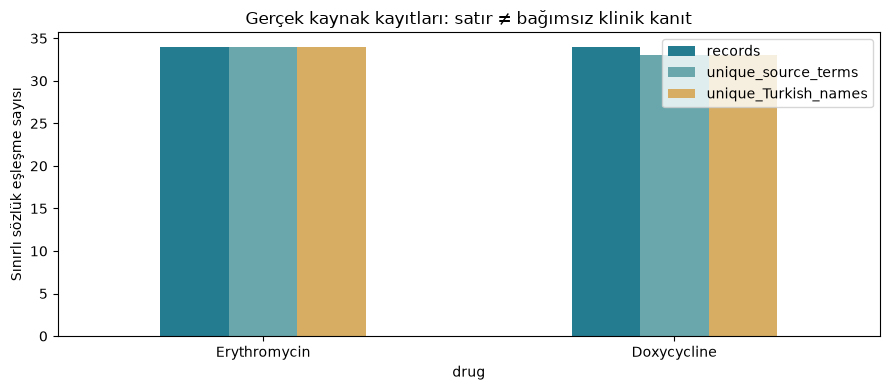

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP13/v1_2';F=ROOT/'reports/figures/WP13/v1_2'
counts=pd.read_csv(Q/'candidate_count_summary.csv');display(counts)
display(pd.read_csv(Q/'source_key_allocation.csv'));display(pd.read_csv(Q/'repeated_terms.csv'))
fig,ax=plt.subplots(figsize=(9,4))
counts.set_index('drug')[['records','unique_source_terms','unique_Turkish_names']].plot.bar(ax=ax,color=['#247c91','#69a7ac','#d6ad62'],rot=0)
ax.set(title='Gerçek kaynak kayıtları: satır ≠ bağımsız klinik kanıt',ylabel='Sınırlı sözlük eşleşme sayısı');plt.tight_layout()
plt.savefig(F/'07_actual_candidate_counts.png',dpi=160);plt.show()


**Yorum:** Erythromycin34 terim/34 Türkçe ad; Doxycycline34 satır/33 terim/33 ad. Doxycycline'de ishal hem doğrudan ilaç hem sınıf kapsamında geçer. Bu iki satır bağımsız doğrudan ilaç kanıtı değildir; kaynağı silmeden kapsam ayrı tutulur.

In [2]:

editorial=pd.read_json(Q/'editorial_translations.json')
display(editorial[editorial.source_term.str.contains('BUN|reversible loss of hearing|glossitis',case=False)][['name','scope','frequency_tr','condition_tr','physical_page','source_quote_id','source_exact','review']])
display(pd.read_json(Q/'browser_checks.json',typ='series').to_frame('gerçek_tarayıcı_kontrolü'))


,name,scope,frequency_tr,condition_tr,physical_page,source_quote_id,source_exact,review
21,Geri dönüşlü işitme kaybı,product_specific,Sıklığı bilinmiyor; mevcut verilerden hesaplanamıyor.,İşitme kaybı geri dönüşlü olarak aktarılır; genellikle yüksek dozlarla veya böbrek sorunu olan h...,5,quote:a606c2c9f5d1862695ef31567790df3a34d34aae6ccdd088097c63f2bb6865d8,Other side effects of Erythromycin Tablets include-: \nNot known (frequency cannot be estimated ...,PENDING
39,Glossit,class_level,Bu adayın alıntısında sıklık belirtilmemiş.,Gastrointestinal bildirimler tetrasiklin sınıfında ağızdan ve parenteral kullanım bağlamında akt...,7,quote:d283a098d0f188efdbbee64b1d3c56f54e317439893ab6415e7bde0e40c2eb35,"Gastrointestinal: Anorexia, nausea, vomiting, diarrhea, glossitis, dysphagia, enterocolitis, and...",PENDING
54,BUN artışı,class_level,Bu adayın alıntısında sıklık belirtilmemiş.,"Tetrasiklinlerin antianabolik etkisi BUN artışına yol açabilir. Bugüne kadarki çalışmalar, böbre...",7,quote:9882fd3b194817596c0e2b90da5ab49b7b708ce9db09fe072566f2948593d787,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,PENDING


,gerçek_tarayıcı_kontrolü
app,drug_safety_explorer_v1_2.py
url,http://127.0.0.1:8504
actual_browser,True
picker_changes_candidate_and_source,PASS
table_Glossit_updates_picker_and_detail,PASS
same_Glossit_ID_in_explanation_tab,PASS
BUN_Turkish_exception,PASS
class_scope_visible,PASS
unknown_frequency_hearing_usually,PASS
uncovered_Glossit_NO_saved_LLM,PASS


**Yorum:** BUN istisnası böbrek işlevi bozulmuş hastalara ilişkin cümleyi korur. Sıklığı bilinmeyen kayıt nadir/yaygın yapılmaz. İngilizce asıl kanıt açılır bölümde; editoryal metin ve eski PENDING LLM yanıtı ayrıdır. Glossit için başka adayın LLM metni iliştirilmez.

## OOF tahmin gerçekten eğitim dışında mı?

In [3]:

display(pd.read_csv(Q/'OOF_scope_summary.csv'))
checks=pd.read_csv(Q/'OOF_fold_isolation_checks.csv')
display(checks.groupby('package')[['drug_disjoint','group_disjoint','transform_train_only','target_train_only']].all())
display(pd.read_csv(Q/'OOF_demo_drug_checks.csv').query("package == 'WP10' and model == 'A1P1' and protocol == 'primary'"))
display(pd.read_csv(Q/'prediction_input_leakage_matrix.csv'))


,package,protocol,model,outer_models,OOF_drugs,OOF_rows,min_fold_targets,max_fold_targets
0,WP08,primary,B1,5,54,13964,220,275
1,WP08,primary,B2,5,61,18004,240,326
2,WP08,stress,B1,5,54,13890,211,280
3,WP08,stress,B2,5,61,17970,245,326
4,WP09,primary,G_noPPI,5,61,18004,240,326
5,WP09,primary,G_realPPI,5,61,18004,240,326
6,WP09,primary,G_shuffledPPI_R0,5,61,18004,240,326
7,WP09,primary,G_shuffledPPI_R1,5,61,18004,240,326
8,WP09,primary,G_shuffledPPI_R2,5,61,18004,240,326
9,WP09,stress,G_noPPI,5,61,17970,245,326


,drug_disjoint,group_disjoint,transform_train_only,target_train_only
package,,,,
WP08,True,True,True,True
WP09,True,True,True,True
WP10,True,True,True,True


,drug_id,package,protocol,model,outer_fold,job_key,in_own_model_train,in_train_graph,in_transform_fit,in_outer_test,PT_count
31,DB00254,WP10,primary,A1P1,1,primary_o01_final_A1P1,False,False,False,True,240
35,DB00199,WP10,primary,A1P1,3,primary_o03_final_A1P1,False,False,False,True,318


,alan,kaynak,tahmin_aninda_bilinebilirlik,fit_ve_izolasyon,sinir
0,DrugBank kimliği / tuz / formülasyon,Kaynak kayıt + açık kimlik kontrolü,Evet; eşdeğerlik ayrıca doğrulanır,Birleştirme/salt varsayımı yok,Metadata; sayısal ezberleme girdisi değil
1,"MW, LogP, HBD, HBA, TPSA + maske",WP04 QC / doğrulanmış yapı,Evet; yan etki etiketinden bağımsız,İlgili outer train scaler; yeni ilaçta refit yok,B1/B2/WP09/WP10
2,Atom44 / bağ14 / stereo,WP04 SMILES + sabit WP10 şema,Evet; yapı kaynağı/QC gerekir,Sabit şema; QC54 açık/8 kapalı korunur,WP10; mevcut builder frozen62 dışında reddeder
3,56 protein özelliği,WP05 temiz standart amino asit dizileri,Dizi ve kimlik doğrulanmışsa,Outer train protein fit evreni ve scaler,kalite_skoru yasak
4,Target/enzyme/transporter/carrier,DrugBank kaynak ilişkileri,Kaynakta varsa; bilinmeyen uydurulmaz,Train grafına heldout ilaç/ters ilişki eklenmez,B2 rol özeti; WP09/WP10 dört ayrı readout
5,İnsan PPI700,WP06 strict aynı-taxID STRING,Etiketten bağımsız dış bağlam,Sabit train protein cache; query grafı değiştirmez,23 E.coli ve80 özelliksiz context hariç
6,PT hedef sözlüğü,Kilitli ilgili outer-train seçimi,Çıkış uzayı; girdi değil,>=5 kullanılabilir pozitif ilaç / >=2 grup train-only,Dış ilaç için yeni head/PT eklenmez
7,Prospektüs yan etkileri / SIDER test etiketleri,PDF / değerlendirme referansı,GİRDİ OLARAK YASAK,Tahmin ve yöntem hash kilidinden sonra karşılaştırma,Yokluğu gerçek negatif değil
8,"PT/kategori sayısı, rapor sıklığı, SHAP/Δz, hedef skorları",Hedeften türetilen bilgi,GİRDİ OLARAK YASAK,Baseline referans B0 değişmez; özellik yapılmaz,Sızıntı önleme


**Yorum:** 110 final outer model/fold bağlamı ve ilgili hash/split/fit kayıtları denetlendi. Her ilaç yalnız kendi test fold'unun modeli için eğitim dışıdır; diğer fold modellerinde eğitimde olabilir. Train/query NPZ ayrımı ve scaler fit kimlikleri kontrol edildi. Bu salt okunur kayıt denetimi yeni performans veya evrensel sızıntısızlık kanıtı değildir.

62 ilaç dışı uçtan uca inference adapter'ı henüz yoktur. WP10 builder frozen62 dışındaki kimliği reddeder. B1 sayısal fonksiyonu uygun bir vektörü hesaplayabilir; bu, yeni ilaç kimliği/özellik/QC/preprocessing doğrulamasını sağlamaz. Şimdilik yalnız geçmiş OOF için sınırlı, retrospektif kör kaynak karşılaştırması tasarlanabilir; gerçek dış validasyon değildir.

## Gerçek çalışan arayüzden kanıt

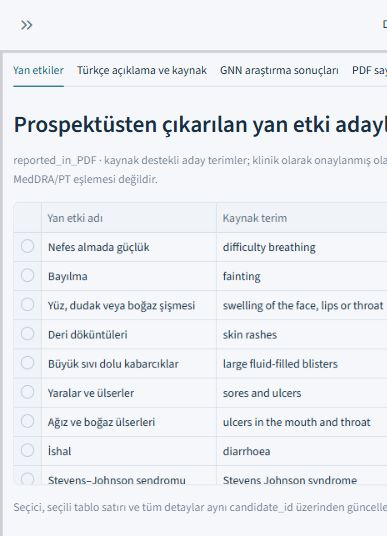

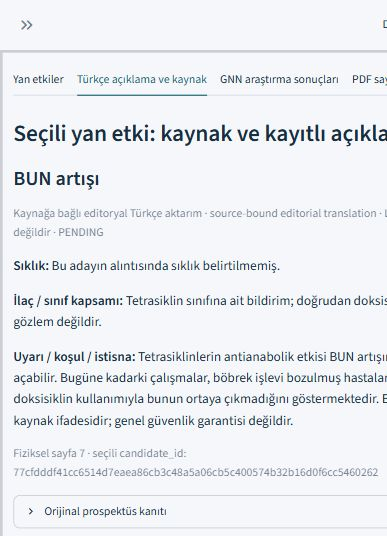

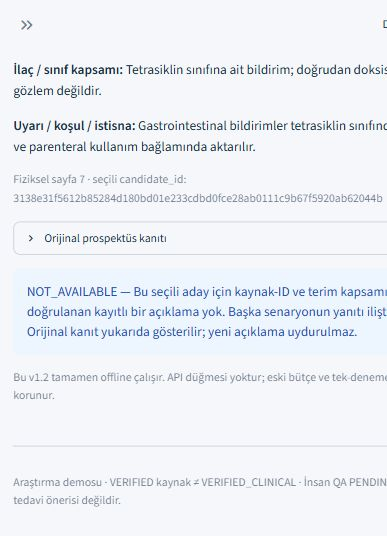

In [4]:

from IPython.display import Image
for name in ['01_erythromycin_Turkish_summary.jpg','05_BUN_editorial_and_saved_LLM.jpg','06_Glossit_no_saved_explanation.jpg']:
    display(Image(filename=str(F/name),width=520))


**Yorum:** Görseller çalışan localhost8504 tarayıcısından alınmıştır; temsili UI veya sentetik skor yoktur. Dar tarayıcı görünümü nedeniyle bazı ekranlar kaydırılmış ayrıntı görünümleridir. Teknik UI başarısı WP12 semantik başarı oranı değildir. Yeni dış antibiyotik denemesi başlatılmadı; insan değerlendirmesi bekleniyor.